# Audio · PCA 3D, K-NN y explicación de resultados

Este cuaderno complementa la guía didáctica. Incluye las **179 grabaciones conservadas de H001–H006**, sin seleccionar solo los ejemplos que se separan bien. La clase es la palabra, no el hablante. Se utiliza el extractor de 160 características: diez segmentos con ZCR, amplitud absoluta y resúmenes de MFCC c1,c2,c4,c5. Los detalles técnicos y el commit consultado están en `datos/procedencia.json`.

Los vectores se reextrajeron de los WAV procesados publicados. El PCA se calculó nuevamente para visualización. Las predicciones y comparaciones LOSO son **evidencia histórica publicada**, no nuevas grabaciones ni una evaluación final independiente. El escalador/PCA global de los gráficos no se utilizó para obtener esas predicciones LOSO.

No se cambian el modelo de audio, k, ejemplos de referencia ni preprocesamiento. Para ejecutar, abrir esta carpeta como directorio de trabajo; los gráficos ya están guardados.


In [1]:
from pathlib import Path
import json, csv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from threadpoolctl import threadpool_limits
D = Path("datos")
z = np.load(D / "audio_desarrollo.npz")
X,y,voces,ids = z["X"],z["y"],z["hablantes"],z["ids"]
Z = StandardScaler().fit_transform(X)
pca = PCA(svd_solver="full").fit(Z)
P = pca.transform(Z)
clases = ["identificar","reconocer","salir"]
colores = {"identificar":"#2563EB","reconocer":"#0D9488","salir":"#9333EA"}
plt.rcParams.update({"font.size":12,"figure.dpi":120,
                     "axes.spines.top":False,"axes.spines.right":False})
def leer_csv(nombre):
    with (D/nombre).open(encoding="utf-8-sig") as f:
        return list(csv.DictReader(f))


## 1. PCA por palabra · tres clases, dos perspectivas

Cada punto es una grabación. PC1, PC2 y PC3 son combinaciones de las 160 características estandarizadas. Las dos vistas muestran las mismas coordenadas desde ángulos distintos. El gráfico no usa etiquetas para calcular los ejes: el color se añade después.

PC1–PC2 explica aproximadamente 27,75 %; las tres primeras alcanzan 37,33 %. Que los colores se mezclen no demuestra que K-NN falle: su decisión utiliza las 160 características, no estas tres coordenadas. No dibujamos esferas: este modelo no tiene centroides ni un umbral de rechazo acústico calibrado.


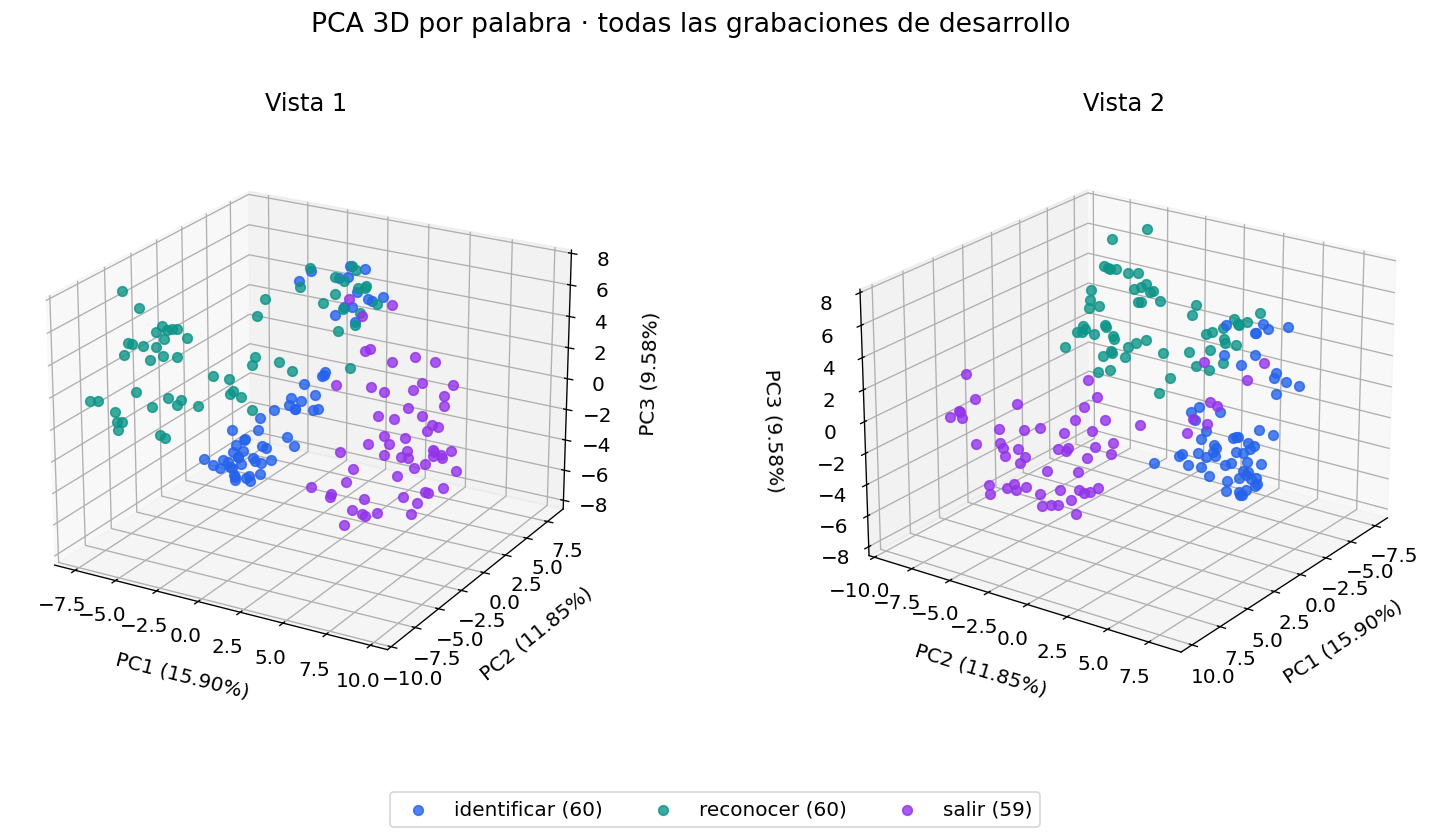

In [2]:
fig=plt.figure(figsize=(16,7))
for panel,azimut in enumerate([-60,35],1):
    ax=fig.add_subplot(1,2,panel,projection="3d")
    for clase in clases:
        m=y==clase
        ax.scatter(P[m,0],P[m,1],P[m,2],color=colores[clase],s=33,alpha=0.8,
                   label=f"{clase} ({m.sum()})",depthshade=False)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%})",labelpad=10)
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%})",labelpad=10)
    ax.set_zlabel(f"PC3 ({pca.explained_variance_ratio_[2]:.2%})",labelpad=10)
    ax.view_init(elev=22,azim=azimut);ax.set_title(f"Vista {panel}")
handles,labels=ax.get_legend_handles_labels()
fig.legend(handles,labels,loc="lower center",ncol=3)
fig.suptitle("PCA 3D por palabra · todas las grabaciones de desarrollo",fontsize=16)
fig.subplots_adjust(bottom=0.15,top=0.85,wspace=0.22);plt.show()


## 2. Mismo PCA por hablante · ¿cuánto cambia la voz?

Las coordenadas no cambian respecto del gráfico anterior. Ahora el color indica quién habló. Esto permite observar si algunas zonas están influidas por la voz. Un agrupamiento visual por hablante no prueba por sí solo que la palabra sea irreconocible. La evaluación LOSO complementa el gráfico con una prueba de clasificación dejando una voz fuera.


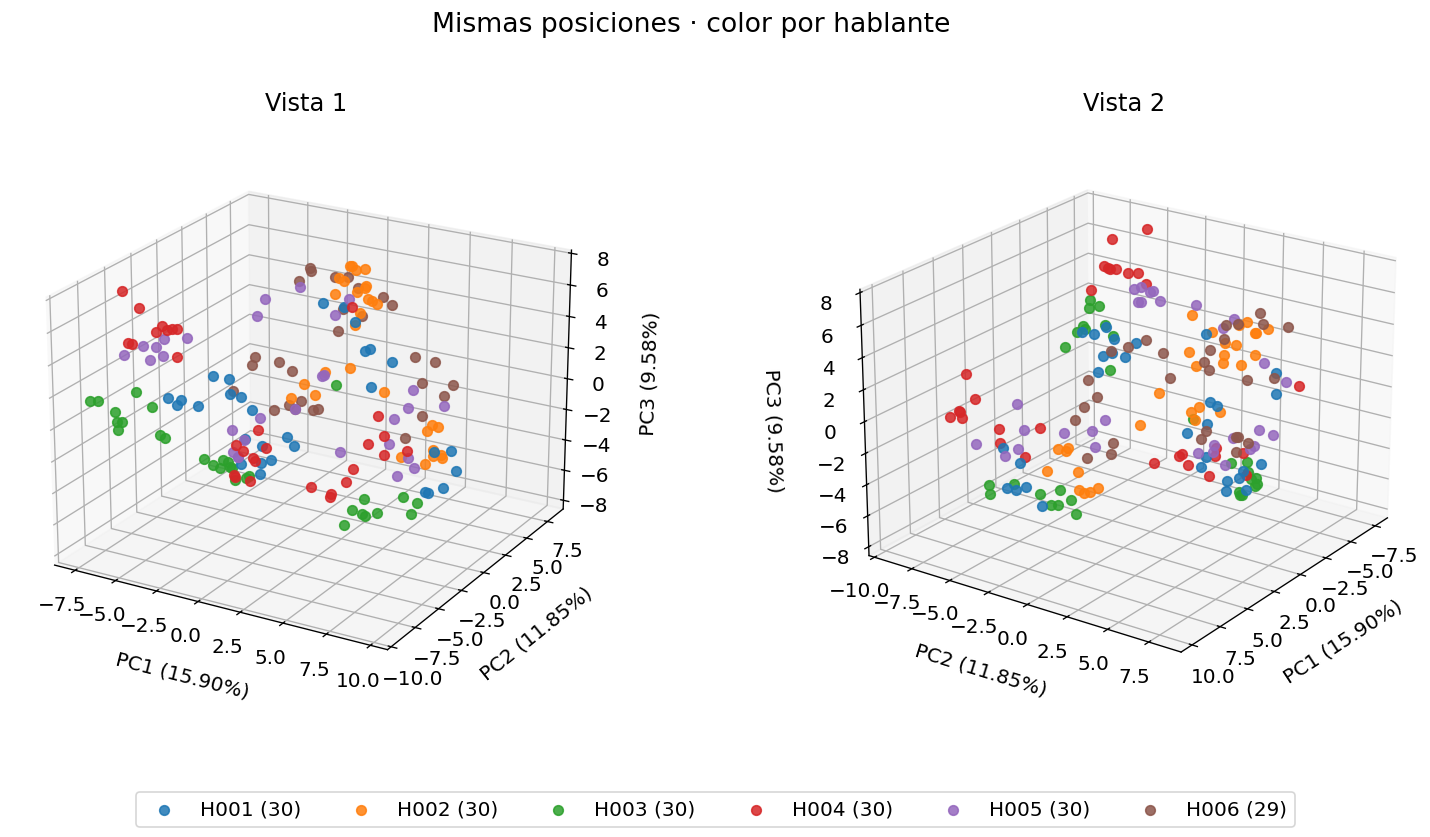

In [3]:
fig=plt.figure(figsize=(16,7));paleta=plt.get_cmap("tab10")
for panel,azimut in enumerate([-60,35],1):
    ax=fig.add_subplot(1,2,panel,projection="3d")
    for i,voz in enumerate(np.unique(voces)):
        m=voces==voz
        ax.scatter(P[m,0],P[m,1],P[m,2],color=paleta(i),s=33,alpha=0.85,
                   label=f"{voz} ({m.sum()})",depthshade=False)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%})",labelpad=10)
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%})",labelpad=10)
    ax.set_zlabel(f"PC3 ({pca.explained_variance_ratio_[2]:.2%})",labelpad=10)
    ax.view_init(elev=22,azim=azimut);ax.set_title(f"Vista {panel}")
handles,labels=ax.get_legend_handles_labels();fig.legend(handles,labels,loc="lower center",ncol=6)
fig.suptitle("Mismas posiciones · color por hablante",fontsize=16)
fig.subplots_adjust(bottom=0.15,top=0.85,wspace=0.22);plt.show()


## 3. Cuánta información deja fuera el dibujo

La varianza acumulada indica cuánta variación conserva cada cantidad de componentes, no el porcentaje de aciertos. Se necesitan 52 para alcanzar 95 %. El resto no equivale automáticamente a ruido: podría contener diferencias útiles para clasificar.

Usar más componentes en una figura no altera el modelo. Para evaluar una variante que clasifique con PCA habría que ajustar escalador y PCA dentro de cada vuelta LOSO y comparar contra la referencia de 160 columnas.


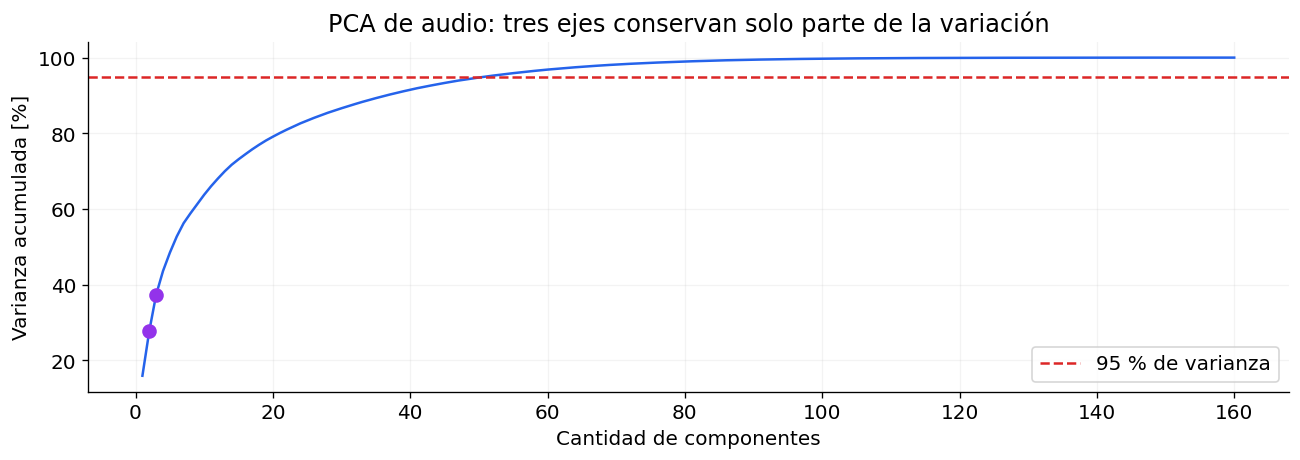

PC1–PC2: 27.75 % · PC1–PC3: 37.33 %
Componentes para 95 %: 52


In [4]:
acum=pca.explained_variance_ratio_.cumsum()*100
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(np.arange(1,len(acum)+1),acum,color="#2563EB")
ax.scatter([2,3],[acum[1],acum[2]],color="#9333EA",s=60,zorder=4)
ax.axhline(95,color="#DC2626",ls="--",label="95 % de varianza")
ax.set(xlabel="Cantidad de componentes",ylabel="Varianza acumulada [%]",title="PCA de audio: tres ejes conservan solo parte de la variación")
ax.legend();ax.grid(alpha=0.15);plt.tight_layout();plt.show()
print(f"PC1–PC2: {acum[1]:.2f} % · PC1–PC3: {acum[2]:.2f} %")
print("Componentes para 95 %:", int(np.searchsorted(acum,95)+1))


## 4. Elegir k no es lo mismo que consultar una grabación

Se probaron k=1,3,5,7 con voto uniforme y por distancia. En LOSO se apartan los audios de una persona y se clasifica usando solo los de las otras cinco. Cada vuelta calcula su escalador sin la voz retenida. Se promedia el recall de las palabras dentro de cada voz y luego entre voces.

Ganó k=1 uniforme, con 169/179 aciertos históricos (94,41 %) y recall macro medio por hablante 94,38 %. Si dos configuraciones empatan en ese criterio a tolerancia 1e-12, el proyecto prefiere uniforme y después menor k. Esto es selección de parámetros, no desempate entre vecinos de una consulta.

La CV se usó para elegir la configuración; no es una evaluación final independiente. Después se guardó un modelo con los 179 ejemplos, sus etiquetas y el escalado global de desarrollo.


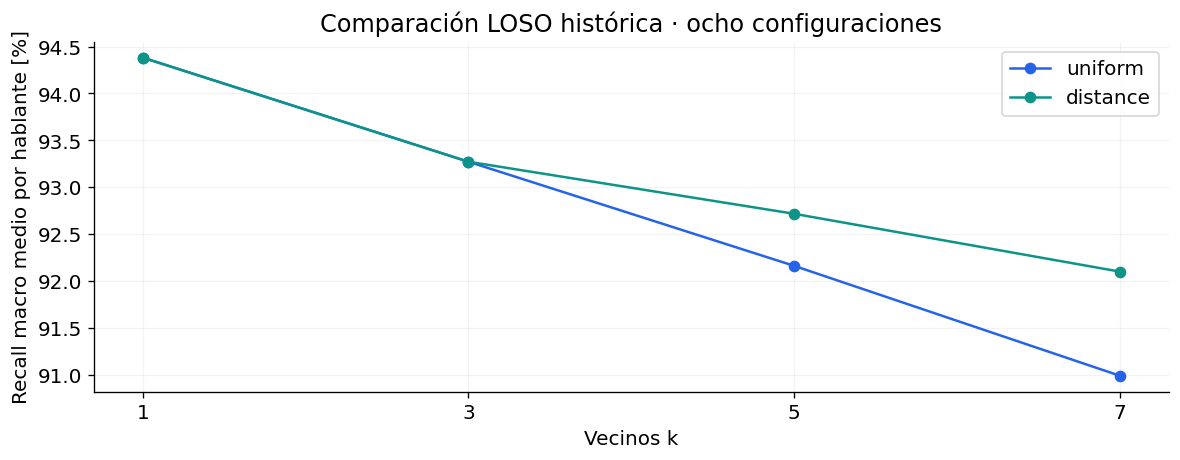

In [5]:
comparacion=leer_csv("comparacion_cv.csv")
fig,ax=plt.subplots(figsize=(10,4))
for voto,color in [("uniform","#2563EB"),("distance","#0D9488")]:
    sub=[r for r in comparacion if r["votos"]==voto]
    ax.plot([int(r["k"]) for r in sub],[100*float(r["recall_macro_medio"]) for r in sub],"o-",color=color,label=voto)
ax.set_xticks([1,3,5,7]);ax.set(xlabel="Vecinos k",ylabel="Recall macro medio por hablante [%]",title="Comparación LOSO histórica · ocho configuraciones")
ax.legend();ax.grid(alpha=0.15);plt.tight_layout();plt.show()


## 5. Errores por palabra y por hablante

La matriz usa filas reales y columnas predichas. Recall pregunta qué proporción de una palabra verdadera se recuperó; precisión pregunta qué proporción de las respuestas de esa palabra eran correctas. Identificar tiene recall 60/60, pero precisión 60/67: otras palabras fueron confundidas con ella.

Las barras por hablante muestran diferencias que un promedio puede ocultar. Los diez errores se conservan; no se eliminan audios por empeorar las métricas.


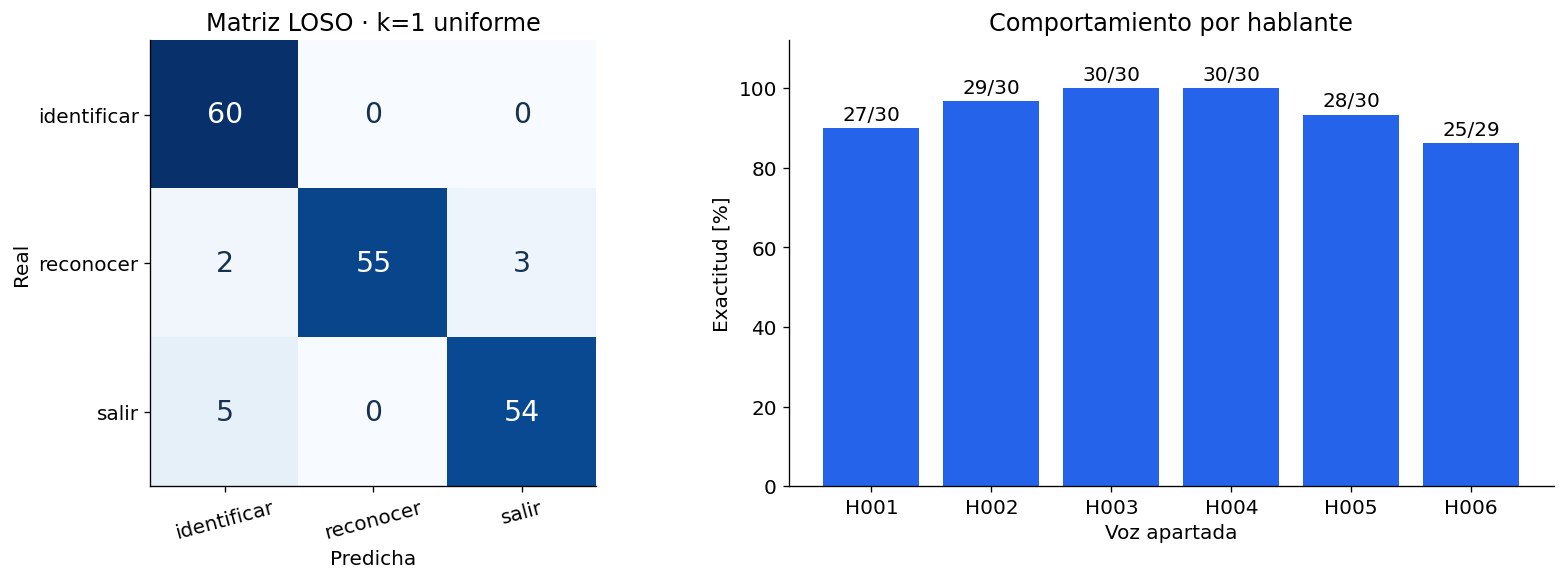

In [6]:
pred=leer_csv("predicciones_cv_seleccion.csv")
matriz=np.zeros((3,3),dtype=int)
for r in pred:matriz[clases.index(r["real"]),clases.index(r["prediccion"])]+=1
fig,(ax,barras)=plt.subplots(1,2,figsize=(14,5))
ax.imshow(matriz,cmap="Blues",vmin=0)
for i in range(3):
    for j in range(3):ax.text(j,i,str(matriz[i,j]),ha="center",va="center",fontsize=17,color="white" if matriz[i,j]>30 else "#16324F")
ax.set_xticks(range(3),clases,rotation=15);ax.set_yticks(range(3),clases)
ax.set(xlabel="Predicha",ylabel="Real",title="Matriz LOSO · k=1 uniforme")
vo=sorted(set(r["hablante"] for r in pred));tasas=[];cuentas=[]
for v in vo:
    sub=[r for r in pred if r["hablante"]==v];ok=sum(r["real"]==r["prediccion"] for r in sub)
    tasas.append(100*ok/len(sub));cuentas.append(f"{ok}/{len(sub)}")
barras.bar(vo,tasas,color="#2563EB")
for i,(t,c) in enumerate(zip(tasas,cuentas)):barras.text(i,t+2,c,ha="center")
barras.set(ylim=(0,112),xlabel="Voz apartada",ylabel="Exactitud [%]",title="Comportamiento por hablante")
plt.tight_layout();plt.show()


## 6. ¿Dónde aparecen los errores en PCA?

Se muestran todas las grabaciones coloreadas por palabra real. Un contorno negro marca las diez que LOSO clasificó incorrectamente. Se proyectan con un PCA global descriptivo; cada predicción LOSO proviene de un clasificador/escalador diferente que no incluyó a la persona correspondiente.

No podemos dibujar una frontera única de esas seis evaluaciones como si fueran un solo modelo. Tampoco un error debe verse necesariamente aislado en tres componentes. La posición puede ocultar distancias que sí contribuyeron en las 160 características.


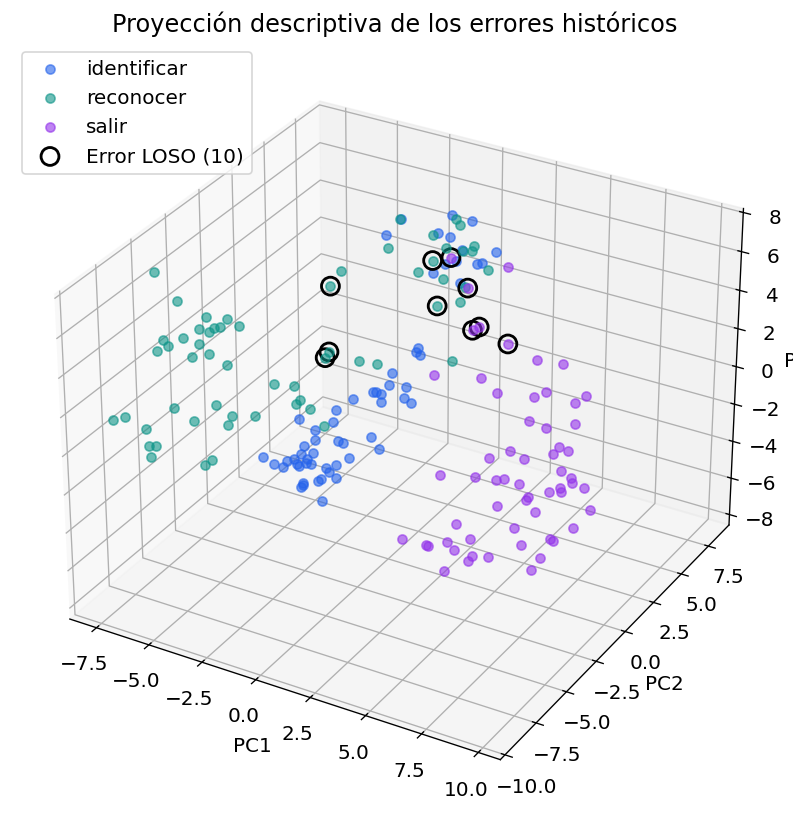

In [7]:
errores={r["muestra"] for r in pred if r["real"]!=r["prediccion"]}
error=np.array([i in errores for i in ids])
fig=plt.figure(figsize=(10,7));ax=fig.add_subplot(projection="3d")
for clase in clases:
    m=y==clase
    ax.scatter(P[m,0],P[m,1],P[m,2],c=colores[clase],s=30,alpha=0.6,label=clase,depthshade=False)
ax.scatter(P[error,0],P[error,1],P[error,2],s=115,facecolors="none",edgecolors="black",linewidths=1.7,label="Error LOSO (10)",depthshade=False)
ax.set_xlabel("PC1");ax.set_ylabel("PC2");ax.set_zlabel("PC3")
ax.set_title("Proyección descriptiva de los errores históricos")
ax.legend(loc="upper left");plt.tight_layout();plt.show()


## 7. Dos vecinos exactamente a igual distancia con k=1

La versión consultada construye `KNeighborsClassifier(n_neighbors=1, weights='uniform', metric='euclidean', algorithm='brute', n_jobs=1)`. La consulta llama a `predict`; no hay una regla propia que detecte igualdad, rechace, consulte más vecinos o solicite repetir.

Con k=1 no hay empate de votos: se selecciona un solo vecino. Si dos ejemplos de clases distintas comparten la menor distancia, la búsqueda debe conservar uno y el resultado puede depender del orden y del procedimiento numérico de la biblioteca. **No aplica automáticamente orden alfabético entre todas las muestras empatadas.** Esa es otra situación distinta del empate de puntuaciones entre clases con varios vecinos.

El siguiente ensayo es hipotético, no un audio real. Usa dos vectores de 160 coordenadas, uno en -1 y otro en +1 en la primera coordenada; las restantes son cero. La consulta es el origen y ambos están a distancia 1. Con la configuración del proyecto y scikit-learn 1.8.0, en este ensayo se eligió el primer ejemplo: al invertir el orden, cambió la respuesta. El notebook imprime lo observado en el entorno donde se ejecute; no promete esa prioridad como contrato universal.

Los IDs, hablantes y etiquetas no se incorporan a la distancia. Distancias que se ven iguales después de redondear tampoco garantizan igualdad interna.


In [8]:
ejemplos=np.zeros((2,160));ejemplos[0,0]=-1;ejemplos[1,0]=1
etiquetas=np.array(["reconocer","salir"]);consulta=np.zeros((1,160))
for orden in [np.array([0,1]),np.array([1,0])]:
    modelo=KNeighborsClassifier(n_neighbors=1,weights="uniform",metric="euclidean",algorithm="brute",n_jobs=1)
    modelo.fit(ejemplos[orden],etiquetas[orden])
    with threadpool_limits(limits=1):
        palabra=modelo.predict(consulta)[0]
        dist,vecino=modelo.kneighbors(consulta)
    print("Orden:",etiquetas[orden].tolist(),"→ respuesta:",palabra,
          "· distancia:",float(dist[0,0]),"· posición elegida:",int(vecino[0,0]))


Orden: ['reconocer', 'salir'] → respuesta: reconocer · distancia: 1.0 · posición elegida: 0
Orden: ['salir', 'reconocer'] → respuesta: salir · distancia: 1.0 · posición elegida: 0


## Para explicarle al profesor

El modelo actual no tiene un rechazo acústico calibrado. Una palabra desconocida vectorizable puede recibir uno de los comandos, aunque su vecino esté lejos. Un voto de k=1 no es 100 % de confianza. La distancia tampoco es una probabilidad.

La gráfica PCA estudia estructura, no certifica precisión. La evidencia LOSO compara alternativas dentro de desarrollo y las nuevas personas siguen siendo necesarias para evaluar generalización. Los ensayos con voz conocida y voces sintéticas no sustituyen esa evaluación.

Fuentes: [implementación de K-NN del proyecto](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/main/src/knn_audio.py), [cierre de audio](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/main/documentos/etapas/cierre_etapa07.md), [advertencia oficial de scikit-learn sobre vecinos equidistantes](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html). El código local consultado y su commit quedan registrados en procedencia.json.
